# Global Solution · Classificação de ocorrências

Aprendizado Profundo com Redes Neurais Convolucionais

Matheus Costa Cutrim 568087 2CCPR

## 1. Objetivo e fonte
Classificar furto ou roubo de celular, condicionado à existência de uma ocorrência. Este notebook precisa ser executado com dados oficiais. Não contém resultados empíricos pré-calculados.

Fonte [SSP-SP](https://www.portal.ssp.sp.gov.br/estatistica/consultas), Bases de Dados → Celulares subtraídos → 2024. Baixe o XLSX e coloque em dados/celulares_2024.xlsx.

### Como executar este notebook no Google Colab

1. Baixe o arquivo `modelo.py` no repositório deste projeto.
2. Baixe a planilha **Celulares subtraídos — 2024** no
   [Portal da SSP-SP](https://www.portal.ssp.sp.gov.br/estatistica/consultas)
   e renomeie o arquivo para `celulares_2024.xlsx`.
3. Na aba **Arquivos** do Colab, envie `modelo.py` e `celulares_2024.xlsx`
   para a pasta principal da sessão (`/content`).
4. Selecione **Ambiente de execução → Executar tudo**. A primeira célula
   organiza a planilha na pasta `dados/`, onde o notebook espera encontrá-la.

Se a sessão do Colab for reiniciada, envie os dois arquivos novamente.

In [2]:
from pathlib import Path

%cd /content

pasta_dados = Path("dados")
pasta_dados.mkdir(exist_ok=True)

planilha = Path("celulares_2024.xlsx")
destino = pasta_dados / planilha.name

if planilha.is_file() and not destino.is_file():
    planilha.rename(destino)

assert Path("modelo.py").is_file(), "Envie modelo.py para /content."
assert destino.is_file(), "Envie celulares_2024.xlsx para /content."

/content


In [3]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
from modelo import prepare, split, experiment, export_web, FEATURES
ARQUIVO = Path('dados/celulares_2024.xlsx')
assert ARQUIVO.exists(), 'Baixe a planilha oficial seguindo o README.'

## 2. Seleção e justificativas
Recorte de fatos em 2024 na capital. Uma unidade por boletim, com exclusão de BOs ambíguos e conflitos de atributos. Amostra estratificada de até 15 mil BOs, semente 42. Bairro e tipo de local representam contexto espacial. Período e dia da semana representam contexto temporal. Não usamos narrativas, rubrica, conduta, dados pessoais ou identificadores como entradas. RUBRICA é usada apenas para o alvo.

,Auditoria
Linhas de origem,412527
Linhas na capital em 2024,221363
Chave de deduplicação,ANO_BO + NUM_BO + ID_DELEGACIA
BOs elegíveis,160569
BOs na amostra,15000


,Bairro,Período,Dia da semana,Tipo de local,classe
283048,VILA CORDEIRO,NÃO INFORMADO,TERÇA,VIA PÚBLICA,0
227803,JARDIM MARILU,NÃO INFORMADO,TERÇA,VIA PÚBLICA,1
321786,FREGUESIA DO O,PELA MANHÃ,SEGUNDA,VIA PÚBLICA,1
317046,PINHEIROS,NÃO INFORMADO,SEXTA,VIA PÚBLICA,1
12657,GRAJAU,DE MADRUGADA,SEXTA,VIA PÚBLICA,0


,0
Bairro,0
Período,0
Dia da semana,0
Tipo de local,0
classe,0


,count
classe,
Furto,8579
Roubo,6421


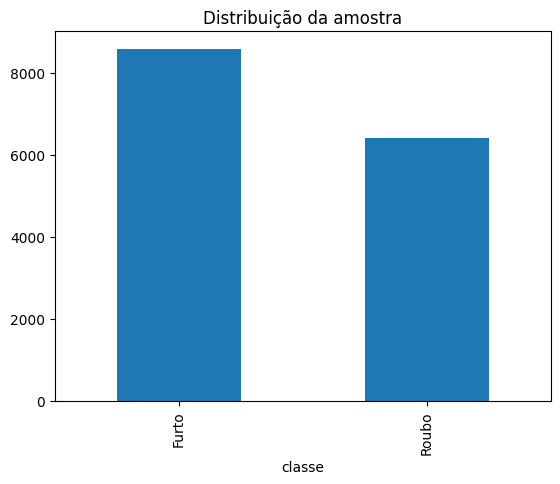

,Bairro
Bairro,
PINHEIROS,526
BELA VISTA,398
BARRA FUNDA,371
BOM RETIRO,328
REPUBLICA,321
ITAIM BIBI,291
SANTANA,280
VILA MARIANA,277
CONSOLACAO,256


,Período
Período,
NÃO INFORMADO,7910
A NOITE,2212
A TARDE,1943
PELA MANHÃ,1832
DE MADRUGADA,1052
EM HORA INCERTA,51


,Dia da semana
Dia da semana,
SÁBADO,2474
SEXTA,2311
QUINTA,2291
QUARTA,2111
TERÇA,2104
DOMINGO,1964
SEGUNDA,1745


,Tipo de local
Tipo de local,
VIA PÚBLICA,11783
TERMINAL/ESTAÇÃO,1461
OUTROS,723
NÃO INFORMADO,422
RESIDÊNCIA,129
COMÉRCIO E SERVIÇOS,80
RESTAURANTE E AFINS,71
ESTACIONAMENTO/GARAGEM,66
LAZER E RECREAÇÃO,47


In [4]:
data, audit = prepare(ARQUIVO)
display(pd.Series(audit, name='Auditoria'))
display(data.head())
display(data.isna().sum())
display(data['classe'].value_counts().rename(index={0:'Furto',1:'Roubo'}))
data['classe'].value_counts().rename(index={0:'Furto',1:'Roubo'}).plot.bar(title='Distribuição da amostra')
plt.show()
for column in FEATURES:
    display(data[column].value_counts().head(10).rename(column))

## 3. Pré-processamento e divisão
Separação estratificada 70/15/15 após deduplicação. Preenchimento categórico constante, sem estatísticas de validação ou teste. One-hot e agrupamento de categorias raras ajustados exclusivamente no treino. Entradas binárias dispensam escalonamento. Categorias desconhecidas recebem vetor nulo no atributo correspondente. A interface usa as categorias disponíveis. Datas ausentes são excluídas, pois impedem o recorte temporal.

In [5]:
train, val, test, encoder = split(data)
display(pd.DataFrame({'treino':train['classe'].value_counts(), 'validacao':val['classe'].value_counts(), 'teste':test['classe'].value_counts()}))
print('Dimensão de entrada:', encoder.transform(train[FEATURES]).shape[1])

,treino,validacao,teste
classe,,,
0,6005,1287,1287
1,4495,963,963


Dimensão de entrada: 178


## 4. Implementação e experimentos
A implementação está em modelo.py, incluindo MLPClassifier, treinamento incremental por época e exportação dos pesos. A saída binária interna é sigmoide e a previsão usa limiar 0,5. ReLU nas camadas ocultas, entropia cruzada binária, Adam, taxa 0,001, L2 0,001, batch 128 e 30 épocas. Arquiteturas A (32), B (64,32) e C (128,64,32). Comparação controlada com os demais parâmetros fixos.

Precision, recall e F1 são médias macro, dando peso igual às duas classes. Seleção por F1 na validação, acurácia e menor profundidade nos desempates. O teste é acessado somente para avaliar a rede selecionada. Uma única semente é uma limitação experimental.

In [6]:
model, results = experiment(train, val, test, encoder)
comparison = pd.DataFrame(results['arquiteturas']).T
display(comparison[['camadas','acuracia','precision','recall','f1']])
print('Modelo escolhido:', results['selecionada'])
print('Baseline majoritário na validação:', results['baseline_validacao'])

,camadas,acuracia,precision,recall,f1
A,"(32,)",0.836,0.832498,0.83769,0.834032
B,"(64, 32)",0.816444,0.812295,0.814714,0.813322
C,"(128, 64, 32)",0.8,0.796135,0.800471,0.797459


Modelo escolhido: A
Baseline majoritário na validação: {'acuracia': 0.572, 'precision': 0.286, 'recall': 0.5, 'f1': 0.3638676844783715}


## 5. Curvas e avaliação final

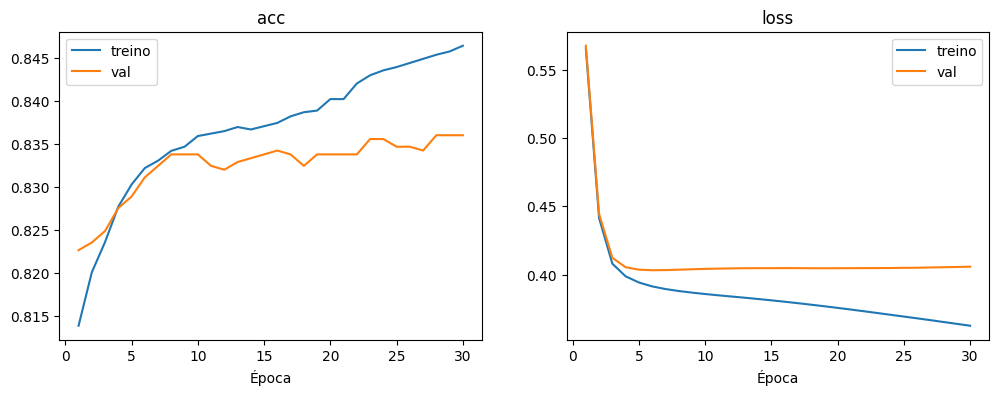

,Teste final
acuracia,0.832889
precision,0.829272
recall,0.834187
f1,0.830800


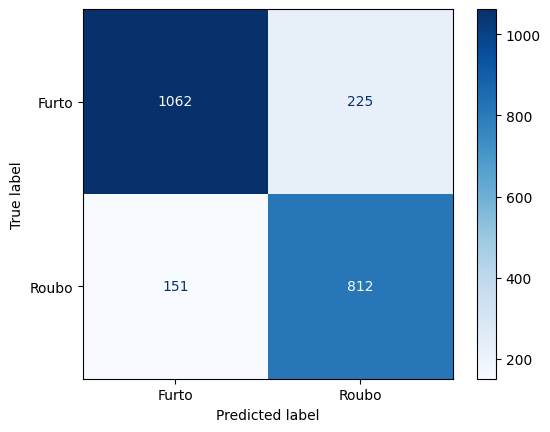

In [8]:
history = pd.DataFrame(results['arquiteturas'][results['selecionada']]['historico'])
fig, axes = plt.subplots(1,2,figsize=(12,4))
for ax, suffix in zip(axes,['acc','loss']):
    for subset in ['treino','val']:
        ax.plot(history['epoca'], history[f'{subset}_{suffix}'],label=subset)
    ax.set_title(suffix)
    ax.set_xlabel('Época')
    ax.legend()
plt.show()
display(pd.Series(results['teste'],name='Teste final'))

import numpy as np
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay(
    confusion_matrix=np.asarray(results["matriz"]),
    display_labels=["Furto", "Roubo"],
).plot(cmap="Blues", values_format="d")

plt.show()

## 6. Interpretação e limitações

A arquitetura A obteve **F1 macro de 0,8340 na validação**, acima de 0,3639 da referência que sempre prevê a classe majoritária. A perda de treinamento continuou diminuindo após as primeiras épocas, enquanto a de validação se estabilizou e voltou a subir ligeiramente. Ao final, a acurácia de treinamento foi de **84,64%**, ante **83,60%** na validação. A diferença de 1,04 ponto percentual, junto ao comportamento da perda, indica um sinal leve de sobreajuste.

No conjunto de teste, a rede classificou corretamente **1.874 dos 2.250 boletins**. A matriz de confusão mostra **225 furtos classificados como roubo** e **151 roubos classificados como furto**. Proporcionalmente ao total de cada classe, o modelo errou **17,5% dos furtos** e **15,7% dos roubos**.

A análise está restrita aos boletins de celulares subtraídos registrados no município de São Paulo em 2024. A subnotificação e as diferenças nas práticas de registro podem afetar os padrões observados. Como o modelo utiliza apenas atributos de contexto, ocorrências de classes diferentes podem apresentar as mesmas características de entrada. As probabilidades exibidas pela aplicação correspondem às saídas da rede e não passaram por calibração.

## 7. Exportação e aplicação web
A aplicação HTML usa o mesmo one-hot, pesos, vieses, ReLU e sigmoide. Não requer backend.

In [9]:
results.update(auditoria=audit, demo=False)
output=Path('docs')
output.mkdir(exist_ok=True)
(output/'resultados.json').write_text(json.dumps(results,ensure_ascii=False,indent=2),encoding='utf-8')
payload=export_web(encoder,model)
payload['demo']=False
(output/'modelo.js').write_text('window.MODELO = '+json.dumps(payload,ensure_ascii=False)+';',encoding='utf-8')
print('Pesos e resultados exportados para docs/.')

Pesos e resultados exportados para docs/.


## 8. Conclusão, relatório e uso de IA

Entre as três arquiteturas avaliadas, a **MLP A**, com uma camada oculta de 32 neurônios, apresentou o maior **F1 macro na validação (0,8340)**. No conjunto de teste, atingiu **83,29% de acurácia** e **0,8308 de F1 macro**. O erro mais frequente foi classificar furto como roubo, o que ocorreu em 225 dos 2.250 boletins de teste.

O relatório técnico reúne a metodologia, a comparação das arquiteturas, as curvas de treinamento, a matriz de confusão e uma demonstração da aplicação web. O README do repositório descreve como reproduzir o treinamento, executar a aplicação e gerar o relatório.

A IA generativa foi utilizada como apoio à implementação do código, à documentação e à revisão técnica. A escolha da arquitetura foi fundamentada nas métricas de validação, e a avaliação final foi realizada no conjunto de teste reservado.